# Evaluate ResNet-56 on CIFAR-10

We’ll use the checkpoints from [Notebook 2](02_train_resnet56.ipynb) to understand how the run progressed and measure how the selected model performs on held-out images. The validation split selected the checkpoint. The test set provides the final estimate on images held out from both training and checkpoint selection.

## 1. Load the saved run

`latest.pth` contains the complete metric history and run settings. `best.pth` contains the weights from the first epoch that reached the highest validation accuracy. We’ll check that they describe the same run and report where the best checkpoint falls in the training history. Both files are created by Notebook 2 under `checkpoints/sgd-paper/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
import torch
from torch.nn import functional as F

cwd = Path.cwd()
project = next(
    path for path in (cwd, *cwd.parents, cwd / "resnet-56")
    if (path / "notebooks" / "03_evaluate_resnet56.ipynb").is_file()
)
sys.path.insert(0, str(project))

from src.data import get_test_loader
from src.training import load_checkpoint, predict

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
folder = project / "checkpoints" / "sgd-paper"
latest_path, best_path = folder / "latest.pth", folder / "best.pth"
if not latest_path.is_file() or not best_path.is_file():
    raise FileNotFoundError("Run Notebook 2 to create checkpoints/sgd-paper/latest.pth and best.pth.")

latest = torch.load(latest_path, map_location="cpu", weights_only=True)
model, best = load_checkpoint(best_path, device)
history, settings = latest["history"], latest["settings"]
best_row = max(history, key=lambda row: row["val_accuracy"])

assert latest["step"] == settings["total_steps"], "The training run is incomplete."
assert best["settings"] == settings and torch.equal(best["mean_image"], latest["mean_image"])
assert best["step"] == best_row["step"] and best["best_val_accuracy"] == best_row["val_accuracy"]

print(f"Finished {latest['step']:,} updates in {history[-1]['epoch']} epochs.")
print(f"Best checkpoint: epoch {best_row['epoch']}, update {best['step']:,}.")
print(f"Best validation accuracy: {best_row['val_accuracy']:.2f}%")
print(f"Final validation accuracy: {history[-1]['val_accuracy']:.2f}%")

Finished 64,000 updates in 182 epochs.
Best checkpoint: epoch 176, update 61,952.
Best validation accuracy: 93.52%
Final validation accuracy: 93.30%


## 2. Read the learning curves

Accuracy is the fraction of images classified correctly. Cross-entropy also responds to confidence, so a confident mistake can raise loss even when accuracy changes little. The loss plot uses a log scale to keep the late training values visible.

Each point summarizes the batches seen in that epoch. The dashed lines mark the paper’s learning-rate drops at **32,000** and **48,000** optimizer updates. The dotted line and dot mark the checkpoint selected by validation accuracy. The final epoch ends partway through a pass when the run reaches 64,000 updates. [ResNet paper, §4.2](https://arxiv.org/pdf/1512.03385#page=7)

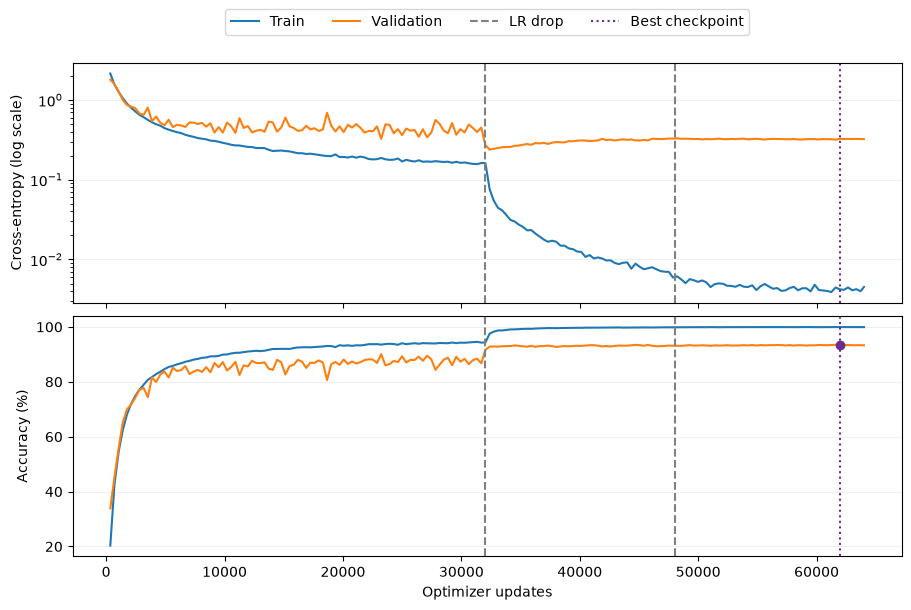

In [2]:
steps = [row["step"] for row in history]
fig, (loss_ax, accuracy_ax) = plt.subplots(2, 1, sharex=True, figsize=(9, 6), layout="constrained")

for ax, metric, ylabel in (
    (loss_ax, "loss", "Cross-entropy (log scale)"),
    (accuracy_ax, "accuracy", "Accuracy (%)"),
):
    ax.plot(steps, [row[f"train_{metric}"] for row in history], label="Train")
    ax.plot(steps, [row[f"val_{metric}"] for row in history], label="Validation")
    for index, milestone in enumerate(settings["milestones"]):
        ax.axvline(milestone, color="gray", linestyle="--", label="LR drop" if index == 0 else None)
    ax.axvline(best["step"], color="#6b2e8b", linestyle=":", label="Best checkpoint")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.2)

loss_ax.set_yscale("log")
loss_ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.25))
accuracy_ax.scatter(best["step"], best_row["val_accuracy"], color="#6b2e8b", zorder=3)
accuracy_ax.set_xlabel("Optimizer updates")
plt.show()

Validation accuracy rose from **86.74%** just before the first learning-rate drop to **93.10%** by update 35,904. After that, training accuracy continued toward 100% while validation accuracy leveled near 93%.

## 3. Evaluate on the held-out test set

We load the **10,000 CIFAR-10 test images** and use the training mean image stored in the checkpoint for centering. Each image is evaluated in its original view. The model is in evaluation mode, so batch normalization uses its stored running statistics.

The highest logit gives the predicted class. Test accuracy counts correct predictions, test error counts mistakes, and test loss reports how much probability the model assigned to the true classes.

In [3]:
data_root = project / "data"
shared_root = project.parent / "highway-networks" / "data"
if not (data_root / "cifar-10-batches-py").is_dir() and (shared_root / "cifar-10-batches-py").is_dir():
    data_root = shared_root

test_loader = get_test_loader(data_root, best["mean_image"], device, batch_size=settings["batch_size"])
logits, targets = predict(model, test_loader, device)
predictions = logits.argmax(dim=1)
correct = (predictions == targets).sum().item()
test_accuracy = 100 * correct / len(targets)
test_error = 100 - test_accuracy
test_loss = F.cross_entropy(logits, targets).item()

print(f"Test accuracy: {test_accuracy:.2f}% ({correct:,}/{len(targets):,})")
print(f"Test error: {test_error:.2f}%")
print(f"Test loss: {test_loss:.4f}")

Test accuracy: 92.41% (9,241/10,000)
Test error: 7.59%
Test loss: 0.3440


## 4. See which classes the model confuses

A **confusion matrix** puts the true class on each row and the predicted class on each column. The diagonal contains correct predictions. Each off-diagonal entry is a specific error, such as a true cat predicted as a dog. Each CIFAR-10 test class has 1,000 images, so we can compare error counts across rows directly. The colors use a square-root scale to make smaller counts visible, and the cell labels give the actual counts.

Most frequent mistakes
  dog predicted as cat: 84 images
  cat predicted as dog: 69 images
  cat predicted as bird: 31 images


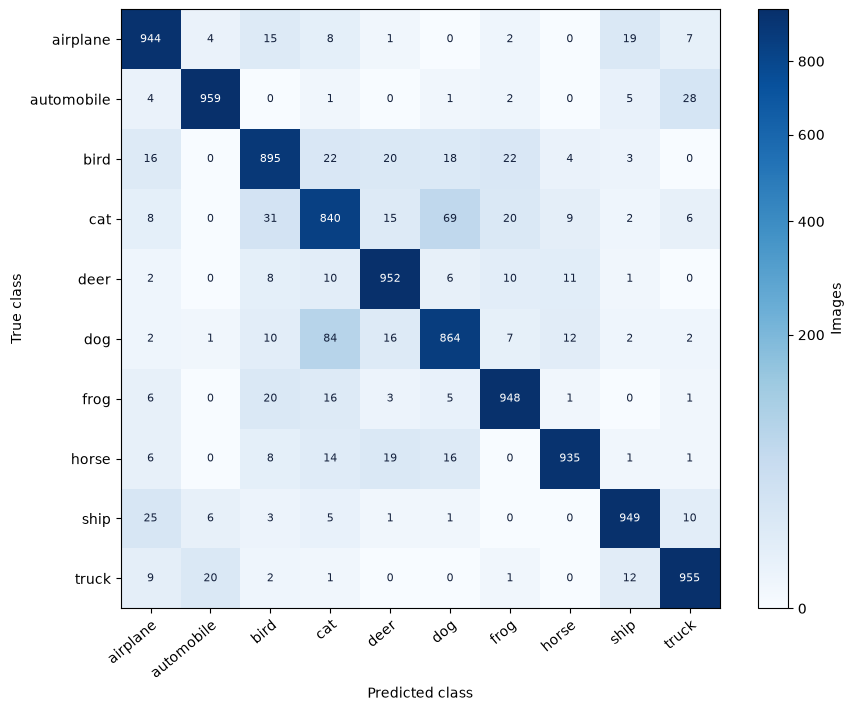

In [4]:
classes = test_loader.dataset.classes
num_classes = len(classes)
confusion = torch.bincount(
    num_classes * targets + predictions, minlength=num_classes ** 2,
).reshape(num_classes, num_classes)
assert confusion.sum().item() == len(targets) and confusion.diag().sum().item() == correct

fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")
heatmap = ax.imshow(confusion.numpy(), cmap="Blues", norm=PowerNorm(gamma=0.5))
ax.set(
    xticks=range(num_classes), yticks=range(num_classes),
    xticklabels=classes, yticklabels=classes,
    xlabel="Predicted class", ylabel="True class",
)
plt.setp(ax.get_xticklabels(), rotation=40, ha="right", rotation_mode="anchor")
fig.colorbar(heatmap, ax=ax, label="Images")
for row, counts in enumerate(confusion.tolist()):
    for col, count in enumerate(counts):
        color = "white" if heatmap.norm(count) > 0.65 else "#14213d"
        ax.text(col, row, str(count), ha="center", va="center", color=color, fontsize=8)
plt.show()

print("Most frequent mistakes")
mistakes = confusion.clone().fill_diagonal_(0)
for pair in mistakes.flatten().topk(3).indices.tolist():
    true_class, predicted_class = divmod(pair, num_classes)
    print(f"  {classes[true_class]} predicted as {classes[predicted_class]}: {mistakes[true_class, predicted_class]} images")

Cats had the lowest class accuracy in this run at **84.0%**. Predictions that confused cats and dogs in either direction accounted for **153 of the 759 test errors**, about one in five.

## 5. Compare with the paper

The recorded run reached **93.52% validation accuracy** and **92.41% test accuracy**. That is **7.59% test error**, which is 0.62 percentage points above the paper’s **6.97%** for ResNet-56. [ResNet paper, Table 6](https://arxiv.org/pdf/1512.03385#page=7)

The architecture and optimizer schedule follow Section 4.2. We trained on 45,000 images and kept 5,000 for checkpoint selection. The paper describes its reported runs as trained on the CIFAR-10 training set and used a 45,000/5,000 split to determine the learning-rate schedule. [ResNet paper, §4.2](https://arxiv.org/pdf/1512.03385#page=7)